# Forecasting models

A model should fit fresh history and return a forecast with explicit axes. Start with transparent baselines, estimate a probabilistic AR(1), then reduce one regressor to multi-step forecasts in three ways.

**Development notebook.** Expand the library cells to edit the implementation. Examples below use local data and CPU. [Build workflow](README.md#develop-the-package-here).

In [1]:
#| default_exp models

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
plt.style.use('default')
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110,
    'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})

## Build `models`

### Imports and configuration

In [3]:
#| export models
from __future__ import annotations
from collections.abc import Sequence
from copy import deepcopy
from timegym._internal import positive_int, nonnegative_int, _real_array

import numpy as np
import pandas as pd
from timegym.contracts import DEFAULT_LEVELS, Forecast


class _ConfiguredForecaster:
    def clone_unfitted(self):
        return type(self)(**self.params())

### _require_regular_future — Step-based models require the next H observations on a regular grid.

In [4]:
#| export models
def _require_regular_future(context_index, future_index):
    """Step-based models require the next H observations on a regular grid."""
    if not isinstance(future_index, pd.Index) or len(future_index) == 0:
        raise ValueError("future_index must be a nonempty pandas Index")
    # One observation cannot establish spacing, regardless of index type.
    if len(context_index) == 1:
        if (not future_index.is_unique or not future_index.is_monotonic_increasing
                or not future_index[0] > context_index[-1]):
            raise ValueError("future_index must be increasing and follow context")
        return
    if isinstance(context_index, (pd.DatetimeIndex, pd.TimedeltaIndex, pd.PeriodIndex)):
        frequency = context_index.freq
        if frequency is None and len(context_index) >= 3:
            frequency = pd.infer_freq(context_index)
        if frequency is None and len(context_index) == 2:
            frequency = context_index[1] - context_index[0]
        if frequency is None:
            raise ValueError("Step-based models require a regular context index with a known frequency")
        constructor = (pd.date_range if isinstance(context_index, pd.DatetimeIndex) else
                       pd.timedelta_range if isinstance(context_index, pd.TimedeltaIndex) else pd.period_range)
        expected_context = constructor(start=context_index[0], periods=len(context_index), freq=frequency)
        expected_future = constructor(start=context_index[-1], periods=len(future_index) + 1, freq=frequency)[1:]
        matches_context = context_index.equals(expected_context)
        matches_future = future_index.equals(expected_future)
    elif pd.api.types.is_numeric_dtype(context_index.dtype):
        values = context_index.to_numpy()
        step = context_index.step if isinstance(context_index, pd.RangeIndex) else (values[1] - values[0] if len(values) >= 2 else None)
        if step is None or step <= 0:
            raise ValueError("Step-based models require a regular context index with a known positive step")
        expected = values[-1] + step * np.arange(1, len(future_index) + 1)
        if pd.api.types.is_float_dtype(context_index.dtype):
            matches_context = bool(np.allclose(np.diff(values), step, rtol=1e-10, atol=0))
            roundoff = 4 * np.finfo(float).eps * max(1, np.max(np.abs(expected)))
            matches_future = (pd.api.types.is_numeric_dtype(future_index.dtype)
                              and np.allclose(future_index.to_numpy(), expected, rtol=0, atol=roundoff))
        else:
            matches_context = bool(np.all(np.diff(values) == step))
            matches_future = (pd.api.types.is_numeric_dtype(future_index.dtype)
                              and np.array_equal(future_index.to_numpy(), expected))
    else:
        raise ValueError("Step-based models require regular numeric, datetime, timedelta, or period indexes")
    if not matches_context:
        raise ValueError("Step-based models require a regular context index")
    if not matches_future:
        raise ValueError("Step-based models require consecutive future labels immediately after context")

### NaiveForecaster — Last value, historical mean, seasonal persistence or endpoint drift.

In [5]:
#| export models
class NaiveForecaster(_ConfiguredForecaster):
    """Last value, historical mean, seasonal persistence or endpoint drift.

    A single observation permits any increasing future index after context;
    its spacing cannot be verified. Longer contexts require a regular grid.
    """

    def __init__(self, strategy="last", period=1):
        strategies = ("last", "mean", "seasonal", "drift")
        if strategy not in strategies:
            raise ValueError(f"Unknown naive strategy {strategy!r}; choose from {strategies}")
        period = positive_int(period, 'period')
        self.strategy, self.period = strategy, period

    def params(self) -> dict:
        """Return the constructor arguments that ``clone_unfitted`` rebuilds from."""
        return dict(strategy=self.strategy, period=self.period)

    def fit(self, context):
        """Keep a copy of the context; raise when it is too short for the strategy."""
        self.context_ = context.copy(deep=True)
        minimum = self.period if self.strategy == "seasonal" else (2 if self.strategy == "drift" else 1)
        if len(context) < minimum:
            raise ValueError("Insufficient context")
        return self

    def predict(self, future_index):
        """Return a point forecast for labels that continue the context's grid."""
        _require_regular_future(self.context_.index, future_index)
        y = self.context_.to_numpy(dtype=float)
        h = len(future_index)
        if self.strategy == "mean":
            point = np.tile(y.mean(axis=0), (h, 1))
        elif self.strategy == "seasonal":
            point = y[-self.period:][np.arange(h) % self.period]
        elif self.strategy == "drift":
            point = y[-1] + np.arange(1, h + 1)[:, None] * (y[-1] - y[0]) / (len(y) - 1)
        else:
            point = np.tile(y[-1], (h, 1))
        return Forecast(index=future_index.copy(), point=point,
                        target_names=tuple(self.context_.columns))

### GaussianAR1Forecaster — OLS AR(1) per target with paired Gaussian innovations.

In [6]:
#| export models
class GaussianAR1Forecaster(_ConfiguredForecaster):
    """Per-target OLS AR(1) with intercept and paired Gaussian innovations.

    Residual innovation covariance is pooled across targets with n-3 degrees
    of freedom for n context observations. The point is the exact iterated
    conditional mean under fitted parameters. Joint samples (256 by default)
    and marginal quantiles at ``levels`` come from a seeded Monte Carlo
    generator. This baseline omits parameter uncertainty and is not a reference.
    """

    def __init__(self, n_samples=256, seed=0, levels=DEFAULT_LEVELS):
        n_samples = positive_int(n_samples, 'n_samples')
        if n_samples < 2:
            raise ValueError('n_samples must be an integer >= 2')
        seed = None if seed is None else nonnegative_int(seed, "seed")
        probabilities = _real_array(levels, "levels")
        if probabilities.ndim != 1 or not probabilities.size:
            raise ValueError("levels must be a nonempty one-dimensional sequence")
        if (not np.isfinite(probabilities).all()
                or np.any((probabilities <= 0) | (probabilities >= 1))):
            raise ValueError("levels must be finite and strictly between zero and one")
        if np.any(np.diff(probabilities) <= 0):
            raise ValueError("levels must be unique and increasing")
        self.n_samples, self.seed = n_samples, seed
        self.levels = tuple(float(value) for value in probabilities)

    def params(self) -> dict:
        """Return the constructor arguments that ``clone_unfitted`` rebuilds from."""
        return dict(n_samples=self.n_samples, seed=self.seed, levels=self.levels)

    def fit(self, context):
        """Fit each target's intercept and AR(1) coefficient, and the shared innovation covariance.

        Needs at least five context rows.
        """
        y = context.to_numpy(dtype=float)
        if len(y) < 5:
            raise ValueError("AR(1) requires at least five context observations")
        self.names_ = tuple(context.columns)
        self.index_ = context.index.copy()
        self.last_ = y[-1].copy()
        coefs = [np.linalg.lstsq(np.column_stack([np.ones(len(y)-1), y[:-1, d]]),
                                y[1:, d], rcond=None)[0] for d in range(y.shape[1])]
        self.intercept_, self.phi_ = np.asarray(coefs).T
        residuals = y[1:] - self.intercept_ - y[:-1] * self.phi_
        self.cov_ = residuals.T @ residuals / (len(residuals) - 2)
        return self

    def predict(self, future_index):
        """Return the iterated mean, seeded joint samples and their marginal quantiles."""
        _require_regular_future(self.index_, future_index)
        h, d = len(future_index), len(self.names_)
        point, samples = np.empty((h, d)), np.empty((self.n_samples, h, d))
        rng = np.random.default_rng(self.seed)
        last_mean, last_samples = self.last_.copy(), np.tile(self.last_, (self.n_samples, 1))
        for i in range(h):
            last_mean = self.intercept_ + self.phi_ * last_mean
            last_samples = self.intercept_ + self.phi_ * last_samples + rng.multivariate_normal(
                np.zeros(d), self.cov_, self.n_samples)
            point[i], samples[:, i] = last_mean, last_samples
        levels = self.levels
        quantiles = np.moveaxis(np.quantile(samples, levels, axis=0), 0, -1)
        return Forecast(index=future_index.copy(), point=point, quantiles=quantiles,
                        levels=levels, samples=samples, target_names=self.names_)

### Reductions and lag windows — Every sklearn reduction trains on the same observed windows.

In [7]:
#| export models
REDUCTIONS = ("recursive", "direct", "multioutput")


def _lag_windows(values, window_length, steps):
    """Pair each flattened lag window, oldest row first, with its next ``steps`` rows.

    Only windows whose labels are rows of ``values`` are returned, so no
    training label lies beyond the last context observation.
    """
    count = len(values) - window_length - steps + 1
    windows = np.asarray([values[i:i + window_length].ravel() for i in range(count)])
    labels = np.asarray([values[i + window_length:i + window_length + steps] for i in range(count)])
    return windows, labels


def _native_multioutput(estimator):
    """Read sklearn's multioutput tag; releases before 1.6 expose it through _get_tags."""
    try:
        from sklearn.utils import get_tags
    except ImportError:
        return bool(estimator._get_tags().get("multioutput", False))
    return bool(get_tags(estimator).target_tags.multi_output)

### SklearnForecaster — Recursive, direct or multioutput reduction; transformations fit only on training windows.

In [8]:
#| export models
class SklearnForecaster(_ConfiguredForecaster):
    """Reduce an sklearn regression pipeline to multi-step forecasts from lag windows.

    Every reduction trains on the same flattened lag windows of the context,
    oldest row first, and fits transformers only on those training rows.
    ``recursive`` fits one-step regressors and appends each prediction to the
    window. ``direct`` fits one regressor per horizon step and target, always
    from the last observed window. ``multioutput`` fits one regressor per
    target for the whole horizon vector, wrapping the final step in
    MultiOutputRegressor when it lacks native multioutput support.
    ``horizon`` is the longest forecast returned; direct and multioutput
    need it to build their labels.
    """

    def __init__(self, steps, window_length=12, reduction="recursive", horizon=None):
        window_length = positive_int(window_length, 'window_length')
        if not isinstance(steps, Sequence) or isinstance(steps, (str, bytes)) or not steps:
            raise ValueError("steps must be a nonempty sequence ending in an sklearn regressor")
        if not is_sklearn_regressor(steps[-1]):
            raise ValueError(f"Final step {steps[-1]!r} must be an sklearn regressor")
        if reduction not in REDUCTIONS:
            raise ValueError(f"Unknown reduction {reduction!r}; choose from {REDUCTIONS}")
        if horizon is not None:
            horizon = positive_int(horizon, 'horizon')
        elif reduction != "recursive":
            raise ValueError(f"The {reduction} reduction requires a positive integer horizon")
        self.steps, self.window_length = list(steps), window_length
        self.reduction, self.horizon = reduction, horizon

    def params(self) -> dict:
        """Return the constructor arguments that ``clone_unfitted`` rebuilds from."""
        return dict(steps=self.steps, window_length=self.window_length,
                    reduction=self.reduction, horizon=self.horizon)

    def _estimator(self, multioutput=False):
        from sklearn.base import clone
        from sklearn.multioutput import MultiOutputRegressor
        from sklearn.pipeline import Pipeline as SkPipeline

        steps = [clone(step) for step in self.steps]
        if multioutput and not _native_multioutput(steps[-1]):
            steps[-1] = MultiOutputRegressor(steps[-1])
        return SkPipeline([(f"step_{i}", step) for i, step in enumerate(steps)])

    def fit(self, context):
        """Fit fresh copies of the steps on lag windows of the context.

        ``recursive`` needs ``window_length + 1`` context rows; ``direct`` and
        ``multioutput`` need ``window_length + horizon``.
        """
        y = context.to_numpy(dtype=float)
        steps = 1 if self.reduction == "recursive" else self.horizon
        if len(y) < self.window_length + steps:
            raise ValueError(f"The {self.reduction} reduction needs at least window_length + {steps} = "
                             f"{self.window_length + steps} context rows")
        self.names_, self.history_ = tuple(context.columns), y.copy()
        self.index_ = context.index.copy()
        windows, labels = _lag_windows(y, self.window_length, steps)
        targets = range(y.shape[1])
        if self.reduction == "direct":
            self.models_ = [[self._estimator().fit(windows, labels[:, step, d]) for step in range(steps)]
                            for d in targets]
        elif self.reduction == "multioutput" and steps > 1:
            self.models_ = [self._estimator(multioutput=True).fit(windows, labels[:, :, d]) for d in targets]
        else:
            self.models_ = [self._estimator().fit(windows, labels[:, 0, d]) for d in targets]
        return self

    def predict(self, future_index):
        """Return a point forecast from the last context window.

        The labels must continue the context's grid; with a ``horizon``, there
        can be at most that many.
        """
        _require_regular_future(self.index_, future_index)
        h = len(future_index)
        if self.horizon is not None and h > self.horizon:
            raise ValueError(f"future_index has {h} labels; this model forecasts at most {self.horizon}")
        window = self.history_[-self.window_length:].reshape(1, -1)
        if self.reduction == "direct":
            predictions = [[models[step].predict(window).item() for models in self.models_] for step in range(h)]
        elif self.reduction == "multioutput":
            predictions = np.column_stack([model.predict(window).reshape(-1)[:h] for model in self.models_])
        else:
            history, predictions = list(self.history_.copy()), []
            for _ in future_index:
                x = np.asarray(history[-self.window_length:]).reshape(1, -1)
                step = np.asarray([model.predict(x).item() for model in self.models_])
                predictions.append(step)
                history.append(step)
        return Forecast(index=future_index.copy(), point=np.asarray(predictions), target_names=self.names_)

### fresh_model — Clone configuration only; never silently copy learned native state.

In [9]:
#| export models
def fresh_model(model):
    """Return a fresh copy of a model for one case, never the caller's object.

    Models with ``clone_unfitted()`` rebuild themselves from configuration;
    sklearn estimators are cloned. Any other instance is deep-copied as
    supplied, so pass it unfitted: TimeGym never fits the original object and
    calls ``fit`` on every copy, so state does not leak between cases unless
    ``fit`` itself reuses state it was given.
    """
    if callable(getattr(model, "clone_unfitted", None)):
        cloned = model.clone_unfitted()
        if cloned is model:
            raise ValueError("clone_unfitted() must return a new model instance")
        return cloned
    if hasattr(model, "get_params"):
        from sklearn.base import clone

        return clone(model)
    return deepcopy(model)

### is_sklearn_regressor — Read estimator tags lazily; sklearn need not be installed for native use.

In [10]:
#| export models
def is_sklearn_regressor(model):
    """Read estimator tags lazily, importing sklearn only when it is needed."""
    if not hasattr(model, "get_params"):
        return False
    from sklearn.base import is_regressor

    return bool(is_regressor(model))

## Compare point forecasts on one realization

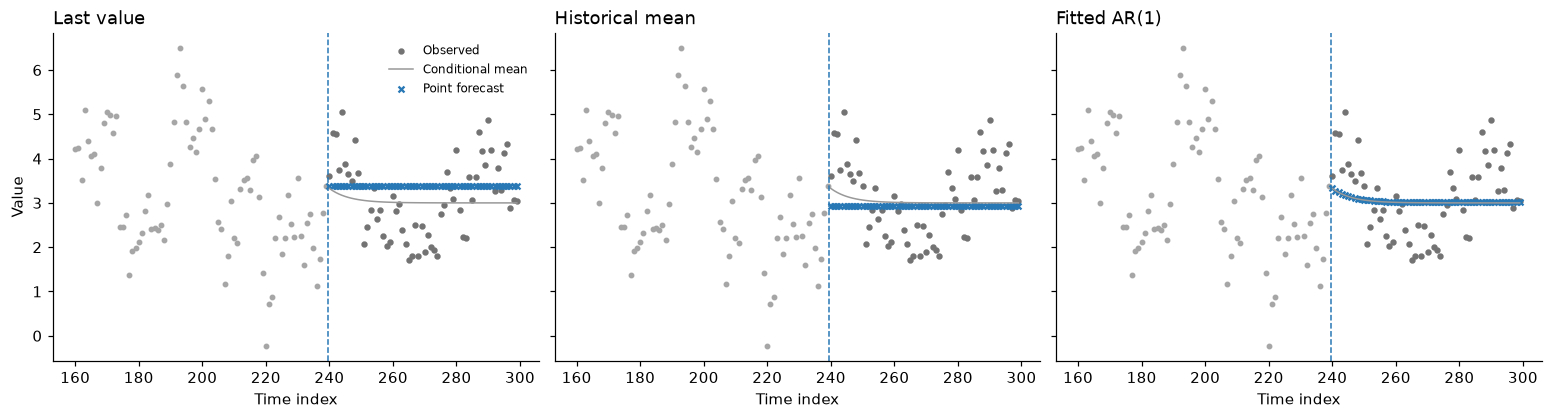

In [11]:
from timegym import Scenario
case = Scenario('ar1', context_length=240, horizon=60,
                parameters={'mean': 3., 'phi': .85, 'sigma': .7}).generate(seed=8)
models = {'Last value': NaiveForecaster('last'), 'Historical mean': NaiveForecaster('mean'),
          'Fitted AR(1)': GaussianAR1Forecaster(n_samples=128, seed=10)}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.7), sharey=True, layout='constrained')
for ax, (name, model) in zip(axes, models.items()):
    forecast = model.fit(case.task.context).predict(case.task.future_index)
    assert forecast.validate(case.task) == []
    ax.scatter(case.task.context.index[-80:], case.task.context['y'].iloc[-80:], s=8, color='.65')
    ax.scatter(case.observed.index, case.observed['y'], s=10, color='.45', label='Observed')
    ax.plot(case.reference.index, case.reference.mean[:, 0], color='.6', lw=1, label='Conditional mean')
    ax.scatter(forecast.index, forecast.point[:, 0], color='#2878b5', marker='x', s=15, label='Point forecast')
    ax.axvline(239.5, color='#2878b5', ls='--', lw=1)
    ax.set(title=name, xlabel='Time index')
axes[0].set_ylabel('Value'); axes[0].legend(fontsize=8)
plt.show()

Future shocks remain unpredictable even when the mean is right. The fitted AR(1) uses diagonal target equations and correlated innovations; its uncertainty excludes parameter-estimation uncertainty. The sklearn adapter uses training-only lag windows; the next example compares its three reductions.

## Three reductions of one regressor

The same scaled Ridge sees the same eight-row lag windows. Recursive feeds each prediction back into the window; direct fits one regressor per horizon step; multioutput fits one regressor for the whole horizon vector. Eight rows cover a third of the 24-step season, so the one-step model is deliberately too short-sighted.

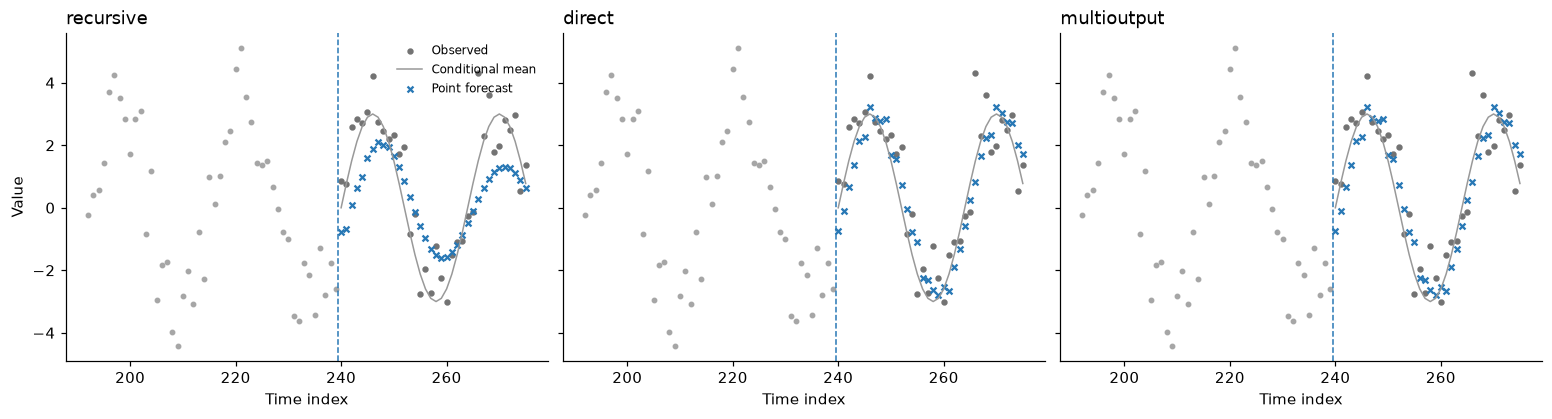

,recursive,direct,multioutput
mean_reference_mse,1.387,0.329,0.329


In [12]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

seasonal_case = Scenario('seasonal', context_length=240, horizon=36,
                         parameters={'amplitude': 3., 'period': 24., 'sigma': 1.}).generate(seed=4)
context, future = seasonal_case.task.context, seasonal_case.task.future_index
reductions = {}
for reduction in REDUCTIONS:
    model = SklearnForecaster([StandardScaler(), Ridge(alpha=1.)], window_length=8,
                              reduction=reduction, horizon=len(future))
    reductions[reduction] = model.fit(context).predict(future)
    assert reductions[reduction].validate(seasonal_case.task) == []
np.testing.assert_allclose(reductions['direct'].point, reductions['multioutput'].point, rtol=1e-8, atol=1e-8)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.7), sharey=True, layout='constrained')
for ax, (reduction, forecast) in zip(axes, reductions.items()):
    ax.scatter(context.index[-48:], context['y'].iloc[-48:], s=8, color='.65')
    ax.scatter(seasonal_case.observed.index, seasonal_case.observed['y'], s=10, color='.45', label='Observed')
    ax.plot(seasonal_case.reference.index, seasonal_case.reference.mean[:, 0], color='.6', lw=1, label='Conditional mean')
    ax.scatter(forecast.index, forecast.point[:, 0], color='#2878b5', marker='x', s=15, label='Point forecast')
    ax.axvline(context.index[-1] + .5, color='#2878b5', ls='--', lw=1)
    ax.set(title=reduction, xlabel='Time index')
axes[0].set_ylabel('Value'); axes[0].legend(fontsize=8)
plt.show()
display(pd.DataFrame({reduction: [((forecast.point - seasonal_case.reference.mean) ** 2).mean()]
                      for reduction, forecast in reductions.items()}, index=['mean_reference_mse']).round(3))

Recursive forecasts lose the seasonal swing as their own predictions fill the window. Direct and multioutput forecasts keep it because every horizon is learned from observed windows. Ridge fits each output by the same penalized least squares, so its multioutput fit equals its direct fit; estimators that share structure across outputs, such as tree ensembles, separate the two. [30 · Reductions](30_reductions.ipynb) repeats the comparison across independent cases.

## Change one thing

Try one parameter or implementation change, rerun the relevant example, and inspect the figure or assertion. Save before exporting. The package tests provide broader regression coverage; the experiment here is intentionally small.